=== PART I: LOADING DATASET ===

--- FIRST 10 ROWS ---
  Request_ID         Service_Type Requester_Type Submission_Date  \
0   REQ-1000           IT Support          Staff      2024-01-01   
1   REQ-1001  Scholarship Inquiry        Student      2024-01-01   
2   REQ-1002              Records        Faculty      2024-01-01   
3   REQ-1003           IT Support        Faculty      2024-01-01   
4   REQ-1004           IT Support          Staff      2024-01-01   
5   REQ-1005  Scholarship Inquiry        Faculty      2024-01-01   
6   REQ-1006              Records        Student      2024-01-01   
7   REQ-1007              Records          Staff      2024-01-01   
8   REQ-1008           IT Support        Student      2024-01-01   
9   REQ-1009        Certification        Student      2024-01-01   

  Requested_Channel Priority  Assigned_Office  Queue_Length  \
0            Portal     High        Registrar            17   
1           Walk-in      Low          Cashier             1   
2      

/tmp/ipykernel_4943/3283588827.py:152: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], data=completed_df, x='Assigned_Office', y='SLA_Breached', errorbar=None, palette='viridis')
/tmp/ipykernel_4943/3283588827.py:158: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1], data=completed_df, x='Queue_Category', y='SLA_Breached', errorbar=None, palette='magma')



Saved EDA visualization to 'eda_charts.png'

=== PART IV: MODEL TRAINING & EVALUATION ===

--- MODEL PERFORMANCE METRICS ---
Confusion Matrix:
[[34  5]
 [ 9  1]]
Accuracy:  0.7143  (Baseline Accuracy: 0.7959)
Precision: 0.1667
Recall:    0.1000
F1-Score:  0.1250

--- TOP 3 INFLUENTIAL FEATURES ---
             Feature  Importance
            SLA_Days    0.255503
        Queue_Length    0.250346
Service_Type_Records    0.142562


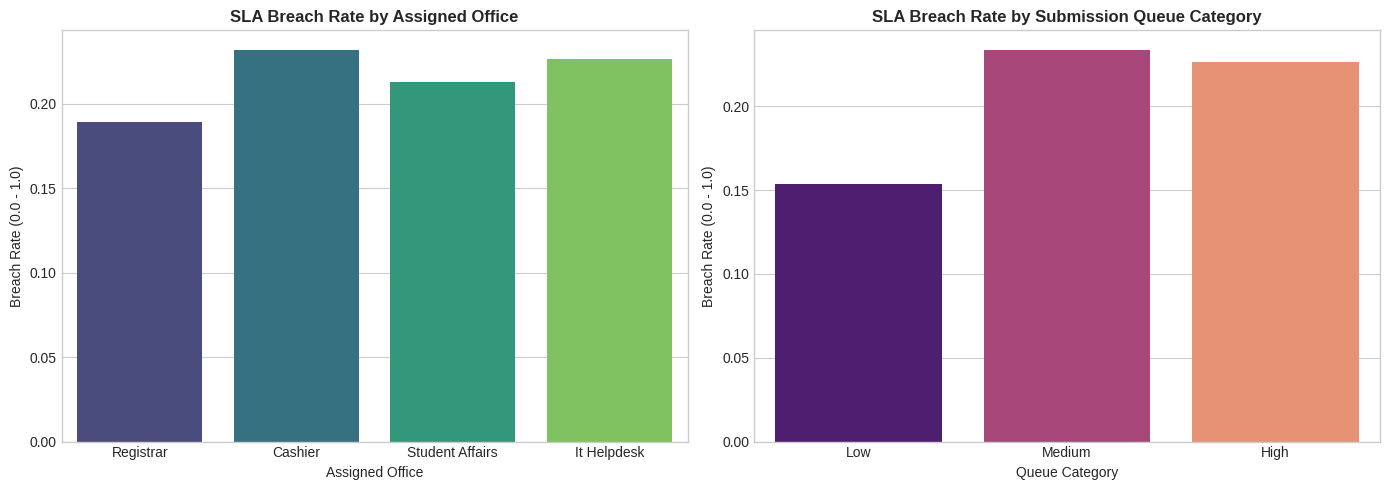

In [9]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# ==========================================
# PART I: DATASET LOADING & INSPECTION
# ==========================================
print("=== PART I: LOADING DATASET ===")

# Load dataset (adjust filename/path if necessary)
file_path = "student_service_requests.csv"

# Fallback synthetic dataset generator if file is missing (for local script execution testing)
if not os.path.exists(file_path):
    print(f"Warning: '{file_path}' not found. Generating synthetic dataset for demonstration...")
    np.random.seed(42)
    n_samples = 400
    synthetic_data = {
        'Request_ID': [f"REQ-{1000+i}" for i in range(n_samples)],
        'Service_Type': np.random.choice(['Records', 'Certification', 'IT Support', 'Scholarship Inquiry'], n_samples),
        'Requester_Type': np.random.choice(['Student', 'Faculty', 'Staff'], n_samples),
        'Submission_Date': pd.date_range(start='2024-01-01', periods=n_samples, freq='h').strftime('%Y-%m-%d'),
        'Requested_Channel': np.random.choice(['Portal', 'Email', 'Walk-in'], n_samples),
        'Priority': np.random.choice(['Low', 'Normal', 'High'], n_samples),
        'Assigned_Office': np.random.choice(['Registrar', 'IT Helpdesk', 'Cashier', 'Student Affairs'], n_samples),
        'Queue_Length': np.random.randint(-2, 25, size=n_samples), # deliberately introducing negative noise
        'Required_Documents_Complete': np.random.choice(['Yes', 'No'], n_samples),
        'Processing_Days': np.random.choice([np.nan, 1, 2, 3, 5, 7, 10, 14], n_samples, p=[0.1, 0.2, 0.2, 0.2, 0.1, 0.1, 0.05, 0.05]),
        'SLA_Days': np.random.choice([3, 5, 7], n_samples),
        'Status': np.random.choice(['Completed', 'Pending', 'Cancelled'], n_samples, p=[0.7, 0.2, 0.1]),
        'Reopened': np.random.choice(['Yes', 'No'], n_samples, p=[0.1, 0.9]),
        'Satisfaction_Score': np.random.choice([1, 2, 3, 4, 5, np.nan], n_samples)
    }
    df = pd.DataFrame(synthetic_data)
else:
    df = pd.read_csv(file_path)

print("\n--- FIRST 10 ROWS ---")
print(df.head(10))

print("\n--- DATASET SHAPE ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n--- DATA TYPES & INFO ---")
print(df.info())

print("\n--- CATEGORY FREQUENCIES ---")
categorical_cols = ['Service_Type', 'Requester_Type', 'Requested_Channel',
                    'Priority', 'Assigned_Office', 'Required_Documents_Complete',
                    'Status', 'Reopened']
for col in categorical_cols:
    if col in df.columns:
        print(f"\nValue Counts for '{col}':")
        print(df[col].value_counts(dropna=False))


# ==========================================
# PART II: DATA CLEANING & FEATURE ENGINEERING
# ==========================================
print("\n=== PART II: DATA CLEANING & FEATURE ENGINEERING ===")

dq_log = []

# 1. Deduplicate Request_ID
dup_count = df.duplicated(subset=['Request_ID']).sum()
if dup_count > 0:
    df = df.drop_duplicates(subset=['Request_ID'], keep='first')
    dq_log.append(f"Removed {dup_count} duplicate Request_ID rows.")

# 2. Standardize Categorical Text Fields
for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip().str.title()

# 3. Clean Dates & Invalid Numerics
df['Submission_Date'] = pd.to_datetime(df['Submission_Date'], errors='coerce')
invalid_dates = df['Submission_Date'].isna().sum()
if invalid_dates > 0:
    df = df.dropna(subset=['Submission_Date'])
    dq_log.append(f"Dropped {invalid_dates} rows with invalid Submission_Date.")

for num_col in ['Queue_Length', 'SLA_Days', 'Processing_Days']:
    if num_col in df.columns:
        neg_mask = df[num_col] < 0
        if neg_mask.sum() > 0:
            df.loc[neg_mask, num_col] = np.nan
            dq_log.append(f"Converted {neg_mask.sum()} negative values in {num_col} to NaN.")

# Impute missing values for submission-time predictors
df['Queue_Length'] = df['Queue_Length'].fillna(df['Queue_Length'].median())
df['SLA_Days'] = df['SLA_Days'].fillna(df['SLA_Days'].median())

# 4. Feature Engineering
df['Submission_Weekday'] = df['Submission_Date'].dt.day_name()

bins = [-1, 5, 15, np.inf]
labels = ['Low', 'Medium', 'High']
df['Queue_Category'] = pd.cut(df['Queue_Length'], bins=bins, labels=labels)

# 5. Create Labeled Dataset (Completed requests with valid Processing_Days & SLA_Days)
completed_df = df[(df['Status'] == 'Completed') &
                  (df['Processing_Days'].notna()) &
                  (df['SLA_Days'].notna())].copy()

completed_df['SLA_Breached'] = (completed_df['Processing_Days'] > completed_df['SLA_Days']).astype(int)

print("\n--- DATA QUALITY LOG ---")
for log_entry in dq_log:
    print("-", log_entry)

# Export cleaned files
df.to_csv("cleaned_all_requests.csv", index=False)
completed_df.to_csv("cleaned_labeled_modeling_set.csv", index=False)
print("Saved 'cleaned_all_requests.csv' and 'cleaned_labeled_modeling_set.csv'")


# ==========================================
# PART III: EXPLORATORY DATA ANALYSIS
# ==========================================
print("\n=== PART III: EXPLORATORY DATA ANALYSIS ===")

# Most requested service type
top_service = df['Service_Type'].value_counts().idxmax()
top_service_count = df['Service_Type'].value_counts().max()
print(f"Most requested service: {top_service} ({top_service_count} requests)")

# Highest breach rate by assigned office
office_breach = completed_df.groupby('Assigned_Office', observed=False)['SLA_Breached'].agg(['count', 'mean'])
highest_breach_office = office_breach['mean'].idxmax()
highest_breach_rate = office_breach['mean'].max()
print(f"Office with highest breach rate: {highest_breach_office} ({highest_breach_rate:.2%})")

# Breach rate by queue category
queue_breach = completed_df.groupby('Queue_Category', observed=False)['SLA_Breached'].agg(['count', 'mean'])
print("\nBreach Rate by Queue Category:")
print(queue_breach)

# Plotting Charts
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Breach Rate by Office
sns.barplot(ax=axes[0], data=completed_df, x='Assigned_Office', y='SLA_Breached', errorbar=None, palette='viridis')
axes[0].set_title('SLA Breach Rate by Assigned Office', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Breach Rate (0.0 - 1.0)')
axes[0].set_xlabel('Assigned Office')

# Chart 2: Breach Rate by Queue Category
sns.barplot(ax=axes[1], data=completed_df, x='Queue_Category', y='SLA_Breached', errorbar=None, palette='magma')
axes[1].set_title('SLA Breach Rate by Submission Queue Category', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Breach Rate (0.0 - 1.0)')
axes[1].set_xlabel('Queue Category')

plt.tight_layout()
plt.savefig('eda_charts.png')
print("\nSaved EDA visualization to 'eda_charts.png'")


# ==========================================
# PART IV: CLASSIFICATION & MODEL EVALUATION
# ==========================================
print("\n=== PART IV: MODEL TRAINING & EVALUATION ===")

# Features permissible at submission time only
features = ['Service_Type', 'Requester_Type', 'Requested_Channel', 'Priority',
            'Assigned_Office', 'Queue_Length', 'Required_Documents_Complete', 'SLA_Days']
X = completed_df[features]
y = completed_df['SLA_Breached']

cat_cols = ['Service_Type', 'Requester_Type', 'Requested_Channel', 'Priority',
            'Assigned_Office', 'Required_Documents_Complete']
num_cols = ['Queue_Length', 'SLA_Days']

# Preprocessing & Pipeline Construction
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ], remainder='passthrough')

clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('tree', DecisionTreeClassifier(max_depth=4, random_state=42))
])

# 80/20 Train-Test Split with Random State 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# Majority-Class Baseline Prediction
majority_class = y_train.mode()[0]
baseline_preds = [majority_class] * len(y_test)

# Metrics Reporting
print("\n--- MODEL PERFORMANCE METRICS ---")
print(f"Confusion Matrix:\n{confusion_matrix(y_test, y_pred)}")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}  (Baseline Accuracy: {accuracy_score(y_test, baseline_preds):.4f})")
print(f"Precision: {precision_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred, pos_label=1, zero_division=0):.4f}")

# Extracting Feature Importance
ohe_feature_names = clf.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(cat_cols)
all_feature_names = list(ohe_feature_names) + num_cols
importances = clf.named_steps['tree'].feature_importances_

importance_df = pd.DataFrame({'Feature': all_feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

print("\n--- TOP 3 INFLUENTIAL FEATURES ---")
print(importance_df.head(3).to_string(index=False))